<a href="https://colab.research.google.com/github/cmd0850/machine_lerning/blob/main/%D0%94%D0%B6%D0%B5%D0%BD%D1%87%D0%B0%D0%BA%D0%BE_%D0%9B%D0%A0_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

### 1. Імпорт бібліотек

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [ ]:
# Варіант 1. Завантаження файлу в Google Colab
# from google.colab import files
# files.upload()
# df = pd.read_csv('data.csv')
# df.head()

In [3]:
# Варіант 2. Завантаження датасету через KaggleHub
import kagglehub
import os
path = kagglehub.dataset_download('unmoved/cure-the-princess')
df = pd.read_csv(os.path.join(path, 'data.csv'))
df.head()

Using Colab cache for faster access to the 'cure-the-princess' dataset.


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [4]:
# TODO: виведіть перші рядки, структуру й розмір датасету
# Підказка: head(), info(), shape
df.head()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB


In [6]:
df.shape

(2338, 14)

In [7]:
# TODO: перевірте кількість пропусків і дублікатів
# Підказка: isnull().sum(), duplicated().sum()
df.isnull().sum()

,0
Phoenix Feather,0
Unicorn Horn,0
Dragon's Blood,0
Mermaid Tears,0
Fairy Dust,0
Goblin Toes,0
Witch's Brew,0
Griffin Claw,0
Troll Hair,0
Kraken Ink,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
# TODO: виведіть описову статистику
# Підказка: describe()
df.describe()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
_Напишіть тут, чи є пропуски, дублікати та які особливості даних помітили._

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [10]:
# TODO: сформуйте X (ознаки) та y (Cured)
# TODO: створіть X_train, X_test, y_train, y_test
# Підказка: train_test_split(..., test_size=0.2, random_state=42)
x=df.drop(columns=['Cured'])
y=df['Cured']
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

### 5. Баланс класів на навчальній вибірці

In [11]:
# TODO: підрахуйте кількість спостережень кожного класу в y_train
y_train.value_counts()

,count
Cured,
0,946
1,924


<Axes: xlabel='Cured', ylabel='count'>

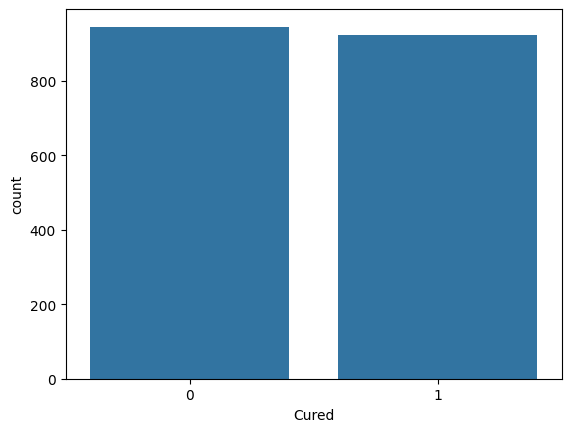

In [12]:
# TODO: побудуйте countplot для y_train
# Підказка: sns.countplot(x=y_train)
sns.countplot(x=y_train)

**Висновок:**  
_Чи збалансовані класи? Чому це може вплинути на оцінку моделі?_

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

<Axes: >

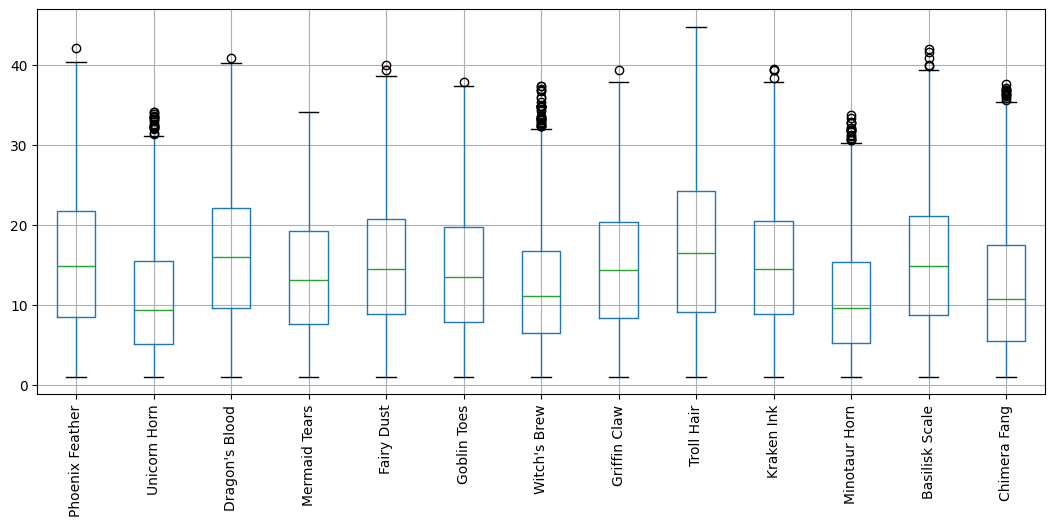

In [13]:
# TODO: побудуйте boxplot для X_train
# Підказка: X_train.boxplot(figsize=(13, 5), rot=90)
X_train.boxplot(figsize=(13, 5), rot=90)

In [14]:
# TODO: обчисліть q1, q3, iqr для X_train
# TODO: знайдіть кількість викидів за межами [q1 - 1.5*iqr, q3 + 1.5*iqr]
# TODO: відсортуйте результат за спаданням
q1=X_train.quantile(0.25)
q1

,0.25
Phoenix Feather,8.500
Unicorn Horn,5.100
Dragon's Blood,9.600
Mermaid Tears,7.600
Fairy Dust,8.800
Goblin Toes,7.800
Witch's Brew,6.400
Griffin Claw,8.300
Troll Hair,9.125
Kraken Ink,8.800


In [15]:
q3=X_train.quantile(0.75)
q3

,0.75
Phoenix Feather,21.700
Unicorn Horn,15.500
Dragon's Blood,22.075
Mermaid Tears,19.200
Fairy Dust,20.775
Goblin Toes,19.675
Witch's Brew,16.700
Griffin Claw,20.400
Troll Hair,24.200
Kraken Ink,20.500


In [16]:
iqr=q3-q1
iqr

,0
Phoenix Feather,13.200
Unicorn Horn,10.400
Dragon's Blood,12.475
Mermaid Tears,11.600
Fairy Dust,11.975
Goblin Toes,11.875
Witch's Brew,10.300
Griffin Claw,12.100
Troll Hair,15.075
Kraken Ink,11.700


In [17]:
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = (X_train < lower) | (X_train > upper)

print(outliers.sum())

Phoenix Feather     1
Unicorn Horn       20
Dragon's Blood      1
Mermaid Tears       0
Fairy Dust          2
Goblin Toes         1
Witch's Brew       33
Griffin Claw        1
Troll Hair          0
Kraken Ink          4
Minotaur Horn      18
Basilisk Scale      5
Chimera Fang       13
dtype: int64


**Висновок про викиди:**  
_У яких ознаках їх найбільше? Чому не варто без перевірки видаляти всі такі рядки?_

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

In [ ]:
# TODO: обчисліть mtx = X_train.corr().abs()
# TODO: створіть маску верхнього трикутника за допомогою np.triu(...)
# TODO: побудуйте sns.heatmap(mtx, mask=..., annot=True, ...)
# Підказка: cmap='Reds', vmin=0, vmax=1
mtx = X_train.corr().abs()


<Axes: >

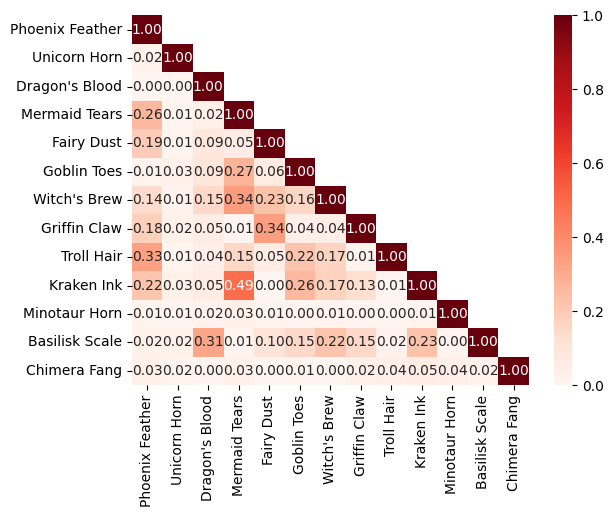

In [ ]:
mask=np.triu(np.ones_like(mtx, dtype=bool), k=1)

sns.heatmap(mtx, mask=mask, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1)

In [19]:
# TODO: дослідіть кореляцію кожної ознаки із Cured
# Підказка: pd.concat([X_train, y_train], axis=1).corr()
corr_pr = (
    pd.concat([X_train, y_train], axis=1)
    .corr()['Cured']
    .abs()
    .drop('Cured')
)

corr_pr.sort_values(ascending=False)


,Cured
Troll Hair,0.488783
Witch's Brew,0.246989
Goblin Toes,0.052573
Chimera Fang,0.047292
Basilisk Scale,0.042277
Kraken Ink,0.026598
Minotaur Horn,0.021922
Phoenix Feather,0.020527
Fairy Dust,0.014223
Dragon's Blood,0.010119


**Висновок про кореляції:**  
_Назвіть пари найбільш корельованих ознак та ознаки з найсильнішим зв’язком із Cured._

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [20]:
# TODO: створіть scaler = StandardScaler()
# TODO: отримайте X_train_scaled і X_test_scaled
scaler = StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [21]:
# TODO: створіть model = LogisticRegression()
# TODO: model.fit(...)
# TODO: отримайте y_pred для X_test_scaled
# TODO: виведіть Accuracy та classification_report
model = LogisticRegression()
model.fit(X_train_scaled, y_train)
y_pred=model.predict(X_test_scaled)
accuracy=accuracy_score(y_test, y_pred)

print('accuracy:', accuracy*100, '%')
print(classification_report(y_test, y_pred))

accuracy: 89.31623931623932 %
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

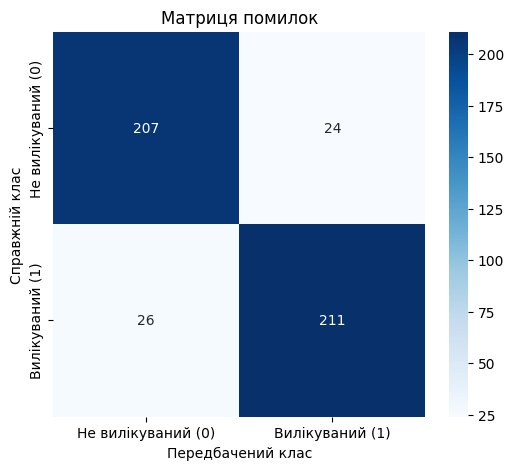

In [22]:
# TODO: обчисліть conf = confusion_matrix(y_test, y_pred)
# TODO: побудуйте теплову карту conf за допомогою sns.heatmap(...)
conf = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    conf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Не вилікуваний (0)', 'Вилікуваний (1)'],
    yticklabels=['Не вилікуваний (0)', 'Вилікуваний (1)']
)
plt.xlabel('Передбачений клас')
plt.ylabel('Справжній клас')
plt.title('Матриця помилок')
plt.show()

In [23]:
# TODO: створіть DataFrame зі справжніми та передбаченими класами
# TODO: виведіть 10 випадкових рядків (sample(10, random_state=42))
results = pd.DataFrame({
    'y_true': y_test.values,
    'y_pred': y_pred
})

results.sample(10, random_state=42)

,y_true,y_pred
55,0,1
63,0,0
33,1,0
297,1,1
72,1,1
228,0,0
209,1,1
9,1,1
428,0,0
231,1,1


**Висновок щодо якості логістичної регресії:**  
_Яких помилок більше? Чи достатньо однієї метрики Accuracy?_

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [24]:
# TODO: створіть словники param_grid і param_dist
# Наприклад, дослідіть кілька значень C, solver та max_iter
param_grid={
    'C':[0.01,0.1,1,10,100],
    'solver':['lbfgs', 'liblinear'],
    'max_iter':[100,200,300]
}
param_dist={
    'solver':['liblinear','lbfgs'],
    'C':np.logspace(-2, 2, 10),
    'max_iter':[100,500]
}

In [25]:
# TODO: створіть GridSearchCV(LogisticRegression(), param_grid, cv=3, ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри
grid=GridSearchCV(LogisticRegression(), param_grid, cv=3, n_jobs=-1, scoring='accuracy', verbose=1)

grid.fit(X_train_scaled, y_train)

print(grid.best_params_)

Fitting 3 folds for each of 30 candidates, totalling 90 fits
{'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}


In [27]:
# TODO: створіть RandomizedSearchCV(LogisticRegression(), ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри

random_search=RandomizedSearchCV(LogisticRegression(), param_distributions=param_dist, n_iter=20, cv=3, n_jobs=-1, scoring='accuracy', verbose=1, random_state=42)
random_search.fit(X_train_scaled,y_train)

print("Найкращі параметри:", random_search.best_params_)
print("Найкраща accuracy (CV):", round(random_search.best_score_, 4))

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Найкращі параметри: {'solver': 'lbfgs', 'max_iter': 100, 'C': np.float64(100.0)}
Найкраща accuracy (CV): 0.8674


In [30]:
# TODO: отримайте найкращу модель з grid або random_search
# TODO: побудуйте прогноз на X_test_scaled
# TODO: виведіть Accuracy та classification_report
best_model=random_search.best_estimator_
y_pred=best_model.predict(X_test_scaled)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred))

Accuracy: 0.8932
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



**Висновок про підбір параметрів:**  
_Який метод пошуку обрав які параметри? Чи покращилась якість порівняно з базовою моделлю?_

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [32]:
# TODO: побудуйте SVC() і DecisionTreeClassifier(random_state=42)
# TODO: навчіть три моделі та отримайте їх передбачення
# TODO: створіть таблицю з Accuracy та F1-score для кожної моделі
# TODO: визначте найкращу модель

svc=SVC()
tree=DecisionTreeClassifier(random_state=42)
log_reg=random_search.best_estimator_

svc.fit(X_train_scaled, y_train)
tree.fit(X_train_scaled, y_train)

models={
    'Logistic Regression': log_reg,
    "SVC": svc,
    "Decision Tree": tree
}

predictions={name: model.predict(X_test_scaled) for name, model in models.items()}

results=pd.DataFrame({
    "Model": list(predictions.keys()),
    "Accuracy": [accuracy_score(y_test, p) for p in predictions.values()],
    "F1-score": [f1_score(y_test, p, average="weighted") for p in predictions.values()]
}).round(4)

print(results)

                 Model  Accuracy  F1-score
0  Logistic Regression    0.8932    0.8932
1                  SVC    0.9594    0.9594
2        Decision Tree    0.8654    0.8654


In [33]:
best_row = results.loc[results["F1-score"].idxmax()]
print(f"\nНайкраща модель: {best_row['Model']} "
      f"(Accuracy = {best_row['Accuracy']}, F1 = {best_row['F1-score']})")


Найкраща модель: SVC (Accuracy = 0.9594, F1 = 0.9594)


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
Дата сет має 13 ознак які описують інгредієнти зілля.Ознаки мають схожий ідапазон значень і кореляції між ними слабкі або помірні. Так підбір гіперпараметрів покращив показники, лоігстична регресія досягла 0.893 після підбору.З усіх моделей найкращоб виявилася SVC з точність та f1 = 0.959, тоді як інші мали 0.865 та 0.893.

---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.